<a href="https://colab.research.google.com/github/AnhNgoc-code/Hoc_May/blob/main/Tuan1_Regression/Buoi1_hoiquytuyentinh_BTVN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bài tập về Nhà
Bài 1


================ SO SÁNH ĐỘ CHÍNH XÁC MÔ HÌNH ================
Công thức gốc lý tưởng: Y = 4 + 3*X

[Kịch bản 1: Độ nhiễu THẤP]
 - Hệ số tìm được: Intercept = 4.07, Slope = 2.90
 - Sai số bình phương trung bình (MSE): 0.1634
 - Hệ số xác định (R2 Score): 0.9507
--------------------------------------------------
[Kịch bản 2: Độ nhiễu CAO (Bài 1 yêu cầu)]
 - Hệ số tìm được: Intercept = 3.71, Slope = 2.96
 - Sai số bình phương trung bình (MSE): 12.9470
 - Hệ số xác định (R2 Score): -0.0415


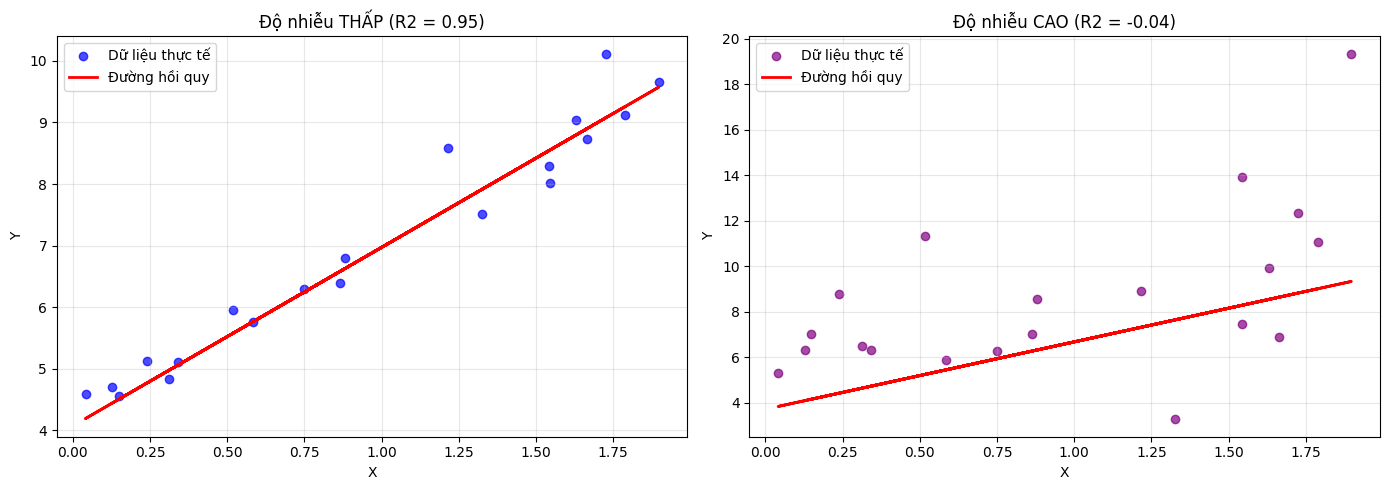

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Cố định seed ngẫu nhiên để kết quả không thay đổi sau mỗi lần chạy
np.random.seed(42)
n_samples = 100

# Tạo biến đầu vào X (ví dụ: Diện tích nhà từ 0 đến 2)
X = 2 * np.random.rand(n_samples, 1)

# Công thức gốc lý tưởng không nhiễu: Y = 4 + 3*X
Y_ideal = 4 + 3 * X

# KỊCH BẢN A: TẠO DỮ LIỆU VỚI ĐỘ NHIỄU THẤP (Low Noise)

noise_low = np.random.randn(n_samples, 1) * 0.5  # Nhiễu nhỏ
Y_low_noise = Y_ideal + noise_low

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X, Y_low_noise, test_size=0.2, random_state=42)

model_low = LinearRegression()
model_low.fit(X_train_l, y_train_l)
y_pred_l = model_low.predict(X_test_l)


# KỊCH BẢN B: TẠO DỮ LIỆU VỚI ĐỘ NHIỄU CAO

noise_high = np.random.randn(n_samples, 1) * 2.5  # Tăng độ nhiễu lên gấp 5 lần
Y_high_noise = Y_ideal + noise_high

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X, Y_high_noise, test_size=0.2, random_state=42)

model_high = LinearRegression()
model_high.fit(X_train_h, y_train_h)
y_pred_h = model_high.predict(X_test_h)



# IN KẾT QUẢ SO SÁNH ĐỘ CHÍNH XÁC CỦA MÔ HÌNH

print("================ SO SÁNH ĐỘ CHÍNH XÁC MÔ HÌNH ================")
print(f"Công thức gốc lý tưởng: Y = 4 + 3*X\n")

print("[Kịch bản 1: Độ nhiễu THẤP]")
print(f" - Hệ số tìm được: Intercept = {model_low.intercept_[0]:.2f}, Slope = {model_low.coef_[0][0]:.2f}")
print(f" - Sai số bình phương trung bình (MSE): {mean_squared_error(y_test_l, y_pred_l):.4f}")
print(f" - Hệ số xác định (R2 Score): {r2_score(y_test_l, y_pred_l):.4f}")
print("-" * 50)

print("[Kịch bản 2: Độ nhiễu CAO (Bài 1 yêu cầu)]")
print(f" - Hệ số tìm được: Intercept = {model_high.intercept_[0]:.2f}, Slope = {model_high.coef_[0][0]:.2f}")
print(f" - Sai số bình phương trung bình (MSE): {mean_squared_error(y_test_h, y_pred_h):.4f}")
print(f" - Hệ số xác định (R2 Score): {r2_score(y_test_h, y_pred_h):.4f}")
print("==============================================================")


# TRỰC QUAN HÓA BẰNG ĐỒ THỊ

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị nhiễu thấp
ax1.scatter(X_test_l, y_test_l, color='blue', alpha=0.7, label='Dữ liệu thực tế')
ax1.plot(X_test_l, y_pred_l, color='red', linewidth=2, label='Đường hồi quy')
ax1.set_title(f"Độ nhiễu THẤP (R2 = {r2_score(y_test_l, y_pred_l):.2f})")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Đồ thị nhiễu cao
ax2.scatter(X_test_h, y_test_h, color='purple', alpha=0.7, label='Dữ liệu thực tế')
ax2.plot(X_test_h, y_pred_h, color='red', linewidth=2, label='Đường hồi quy')
ax2.set_title(f"Độ nhiễu CAO (R2 = {r2_score(y_test_h, y_pred_h):.2f})")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Bài 2


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Giả định y_true là nhãn thực tế, y_proba là xác suất dự đoán được từ mô hình
y_true = np.array([0, 0, 1, 1, 0, 1, 1, 0, 1, 0])
y_proba = np.array([0.15, 0.42, 0.88, 0.63, 0.55, 0.72, 0.48, 0.22, 0.91, 0.34])

# Khảo sát các ngưỡng khác nhau
thresholds = [0.5, 0.6, 0.7]

for t in thresholds:
    # Nếu xác suất >= t thì gán nhãn 1, ngược lại 0
    y_pred = (y_proba >= t).astype(int)

    print(f"--- VỚI NGƯỠNG DỰ ĐOÁN (THRESHOLD) = {t} ---")
    print("Nhãn dự đoán:", y_pred)
    print("Ma trận nhầm lẫn (Confusion Matrix):\n", confusion_matrix(y_true, y_pred))
    print("-" * 40)


--- VỚI NGƯỠNG DỰ ĐOÁN (THRESHOLD) = 0.5 ---
Nhãn dự đoán: [0 0 1 1 1 1 0 0 1 0]
Ma trận nhầm lẫn (Confusion Matrix):
 [[4 1]
 [1 4]]
----------------------------------------
--- VỚI NGƯỠNG DỰ ĐOÁN (THRESHOLD) = 0.6 ---
Nhãn dự đoán: [0 0 1 1 0 1 0 0 1 0]
Ma trận nhầm lẫn (Confusion Matrix):
 [[5 0]
 [1 4]]
----------------------------------------
--- VỚI NGƯỠNG DỰ ĐOÁN (THRESHOLD) = 0.7 ---
Nhãn dự đoán: [0 0 1 0 0 1 0 0 1 0]
Ma trận nhầm lẫn (Confusion Matrix):
 [[5 0]
 [2 3]]
----------------------------------------


Bài 3


In [ ]:
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# lấy bộ dữ liệu cũ
boston = fetch_openml(name='boston', version=1, as_frame=True, parser='auto')
X = boston.data
y = boston.target


X = pd.get_dummies(X, drop_first=True)

# chia dữ liệu để huấn luyện
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# huấn luyện mô hình hồi quy tuyến tính trên tập huấn luyện
model = LinearRegression()
model.fit(X_train, y_train)

# dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Kết quả thu được là:")
print(f"Mean squared error: {mse:.4f}")
print(f"R^2 Score: {r2:.4f}")

Kết quả thu được là:
Mean squared error: 24.8184
R^2 Score: 0.6616
